## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

Total tokens: 276949
Unique tokens: 48691
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


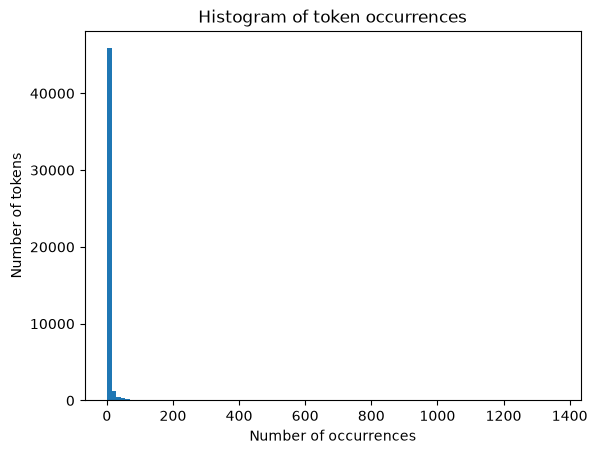

count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
dtype: float64
Share of tokens that appear only once: 0.604


In [4]:
# Your Phase 1 solution to the problem goes here.
# Q1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

counts = [count for token, count in token_freq]

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(counts))
print(token_freq[:10])

plt.hist(counts, bins=100)
plt.xlabel("Number of occurrences")
plt.ylabel("Number of tokens")
plt.title("Histogram of token occurrences")
plt.show()
counts_series = pd.Series(counts)
print(counts_series.describe())
print("Share of tokens that appear only once:", round((counts_series == 1).mean(), 3))

Q1) The histogram is very right-skewed. Almost all of the 48,700 unique tokens are in the first bar near zero, and a long, thin tail runs out to about 1,365 (“new”). About 60% of the tokens show up only once, and the median is 1. Only a few words, like “new”, “date”, “get”, “please” and “enron”, show up hundreds or thousands of times. So most words are rare and a few are very common, which is the long-tail pattern you usually see in text data (kind of like Zipf’s law).

In [5]:
# Q2
df = pd.read_parquet('data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop('Email Type', axis=1)

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

reg = LinearRegression().fit(X_train, y_train)

print("Train R^2:", round(reg.score(X_train, y_train), 3))
print("Test R^2: ", round(reg.score(X_test, y_test), 3))

coef = pd.DataFrame({'variable': reg.feature_names_in_, 'coefficient': reg.coef_})
coef['abs_coef'] = np.abs(coef['coefficient'])
coef.sort_values('abs_coef', ascending=False).head(15)

Train R^2: 0.768
Test R^2:  0.659


,variable,coefficient,abs_coef
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


Q2) The R^2 is about 0.77 on the training set and 0.66 on the test set. The test R^2 is lower, so the model is overfitting some, which makes sense with 2,711 variables.

The words with the largest coefficients are “background-image:” (negative), “localized”, “helvetica,”, “thermal”, “aging” and “transcript” (positive), and “april’s”, “retrieving”, “cnet” and “zdnet” (negative). Many of these are HTML/CSS formatting tokens or fairly rare words, not the obvious scam words I expected. Rare words that only appear in a few emails can get huge coefficients when there are this many variables, so these probably aren’t very reliable on their own.

Variance explained: [0.0111 0.0086]


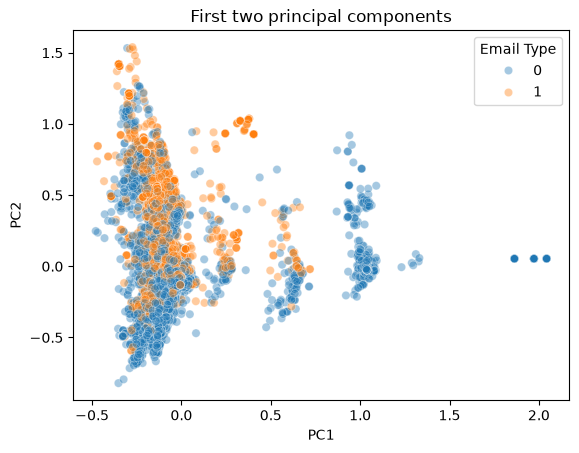

In [6]:
# Q3
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

print("Variance explained:", pca.explained_variance_ratio_.round(4))

pca_df = pd.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1], 'Email Type': y})

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', alpha=0.4)
plt.title("First two principal components")
plt.show()

Q3) The two components only explain about 1.1% and 0.9% of the variance, so a lot of information is lost, and the two classes overlap a lot in the big cluster near the origin. There are still some patterns, though. The phishing emails (1) mostly sit on the left side (low PC1) and tend to have higher PC2 values. The non-scam emails (0) go lower on PC2, and almost all the points stretching out to the right on PC1 (the separate vertical clusters around 0.5, 1 and 2) are legit emails. Those clusters are probably groups of very similar automated work emails, since words like “date”, “url:”, “hour” and “schedules” have the highest PC1 loadings.

In [7]:
# Q4
pca_big = PCA(n_components=2610).fit(X_train)
Z_train = pca_big.transform(X_train)
Z_test = pca_big.transform(X_test)

print("Variance retained:", round(pca_big.explained_variance_ratio_.sum(), 4))

reg_pca = LinearRegression().fit(Z_train, y_train)

print("Train R^2:", round(reg_pca.score(Z_train, y_train), 3))
print("Test R^2: ", round(reg_pca.score(Z_test, y_test), 3))

Variance retained: 0.9998
Train R^2: 0.767
Test R^2:  0.66


Q4) The R^2 is about 0.77 on the training set and 0.66 on the test set. That’s basically the same as the regular linear regression, and the test R^2 is actually a tiny bit higher. This makes sense because 2,610 components keep about 99.98% of the variance in X. The regression gets almost the same information while using about 100 fewer variables.

Q5) Many of the token columns overlap, because certain words show up together in the same kinds of emails, and many of the tokens are rare. A regression on all of them gets noisy coefficients and overfits. PCA turns them into new variables that are uncorrelated with each other and ordered by how much variance they explain. That lets us drop the components with almost no information and use fewer variables while keeping most of the signal. In Q4 we cut about 100 variables and got the same (slightly better) test R². Keeping even fewer components would make the model simpler, faster and less likely to overfit.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]